In [ ]:
!pip install -q tensorflow pandas matplotlib scikit-learn scipy

In [ ]:
import os, random, time
import numpy as np, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.applications import InceptionV3
from scipy.linalg import sqrtm
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, precision_recall_fscore_support)

SEED = 42
def set_seed(s=SEED):
    os.environ['PYTHONHASHSEED'] = str(s)
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)
    tf.keras.utils.set_random_seed(s)
set_seed()
print('TF', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

NORMAL_CLASS = 7          # "normal" deb olinadigan raqam
LATENT_AE, LATENT_GAN = 32, 100
GAN_EPOCHS, GAN_BATCH = 60, 128

TF 2.21.0 | GPU: []


In [ ]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = (x_train.astype('float32') / 255.)[..., None]
x_test  = (x_test.astype('float32') / 255.)[..., None]

x_norm = x_train[y_train == NORMAL_CLASS]                 # faqat normal sinf
rng = np.random.RandomState(SEED)
perm = rng.permutation(len(x_norm))
n_val = int(0.1 * len(x_norm))
x_ae_val, x_ae_tr = x_norm[perm[:n_val]], x_norm[perm[n_val:]]

y_anom = (y_test != NORMAL_CLASS).astype(int)             # 1 = anomaliya
print('AE train:', x_ae_tr.shape, '| val (normal):', x_ae_val.shape)
print('Test: normal', (y_anom == 0).sum(), '| anomaliya', y_anom.sum(),
      '| anomaliya ulushi: %.3f' % y_anom.mean())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
AE train: (5639, 28, 28, 1) | val (normal): (626, 28, 28, 1)
Test: normal 1028 | anomaliya 8972 | anomaliya ulushi: 0.897


In [ ]:
def build_ae():
    set_seed()
    inp = layers.Input((28, 28, 1))
    x = layers.Conv2D(32, 3, strides=2, padding='same', activation='relu')(inp)   # 14x14
    x = layers.Conv2D(64, 3, strides=2, padding='same', activation='relu')(x)     # 7x7
    x = layers.Flatten()(x)
    z = layers.Dense(LATENT_AE, name='latent')(x)                                 # bottleneck
    x = layers.Dense(7 * 7 * 64, activation='relu')(z)
    x = layers.Reshape((7, 7, 64))(x)
    x = layers.Conv2DTranspose(64, 3, strides=2, padding='same', activation='relu')(x)
    x = layers.Conv2DTranspose(32, 3, strides=2, padding='same', activation='relu')(x)
    out = layers.Conv2D(1, 3, padding='same', activation='sigmoid')(x)
    return models.Model(inp, out, name='conv_ae')

def train_ae(x_tr, x_val, epochs=40):
    ae = build_ae()
    ae.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')
    es = tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
    h = ae.fit(x_tr, x_tr, validation_data=(x_val, x_val), epochs=epochs,
               batch_size=128, callbacks=[es], verbose=2)
    return ae, h.history

def score(ae, x):
    rec = ae.predict(x, batch_size=512, verbose=0)
    return np.mean((x - rec) ** 2, axis=(1, 2, 3))        # reconstruction MSE = anomaliya skori

def evaluate_ae(ae, x_val_norm):
    err_val, err_test = score(ae, x_val_norm), score(ae, x_test)
    out = dict(ROC_AUC=roc_auc_score(y_anom, err_test),
               PR_AUC_anomaly=average_precision_score(y_anom, err_test),
               PR_AUC_normal=average_precision_score(1 - y_anom, -err_test))
    sweep = []
    for p in [90, 95, 99]:        # threshold: faqat normal validation xatolarining percentili
        thr = np.percentile(err_val, p)
        pred = (err_test > thr).astype(int)
        pr, rc, f1, _ = precision_recall_fscore_support(y_anom, pred, average='binary', zero_division=0)
        sweep.append(dict(percentile=p, threshold=thr, precision=pr, recall=rc, f1=f1,
                          FPR_on_normal=pred[y_anom == 0].mean()))
    return out, pd.DataFrame(sweep), err_test, err_val

Epoch 1/40
45/45 - 42s - 944ms/step - loss: 0.1107 - val_loss: 0.0539
Epoch 2/40
45/45 - 15s - 326ms/step - loss: 0.0513 - val_loss: 0.0487
Epoch 3/40
45/45 - 10s - 227ms/step - loss: 0.0478 - val_loss: 0.0449
Epoch 4/40
45/45 - 10s - 227ms/step - loss: 0.0355 - val_loss: 0.0265
Epoch 5/40
45/45 - 9s - 197ms/step - loss: 0.0217 - val_loss: 0.0163
Epoch 6/40
45/45 - 10s - 226ms/step - loss: 0.0137 - val_loss: 0.0118
Epoch 7/40
45/45 - 10s - 229ms/step - loss: 0.0102 - val_loss: 0.0096
Epoch 8/40
45/45 - 12s - 269ms/step - loss: 0.0084 - val_loss: 0.0078
Epoch 9/40
45/45 - 19s - 412ms/step - loss: 0.0072 - val_loss: 0.0069
Epoch 10/40
45/45 - 10s - 227ms/step - loss: 0.0063 - val_loss: 0.0063
Epoch 11/40
45/45 - 10s - 217ms/step - loss: 0.0057 - val_loss: 0.0058
Epoch 12/40
45/45 - 9s - 210ms/step - loss: 0.0052 - val_loss: 0.0054
Epoch 13/40
45/45 - 11s - 254ms/step - loss: 0.0049 - val_loss: 0.0050
Epoch 14/40
45/45 - 10s - 228ms/step - loss: 0.0045 - val_loss: 0.0048
Epoch 15/40
45/45

,percentile,threshold,precision,recall,f1,FPR_on_normal
0,90,0.0054,0.9849,0.9043,0.9429,0.1206
1,95,0.0069,0.9906,0.8718,0.9274,0.0720
2,99,0.0122,0.9973,0.7331,0.8450,0.0175


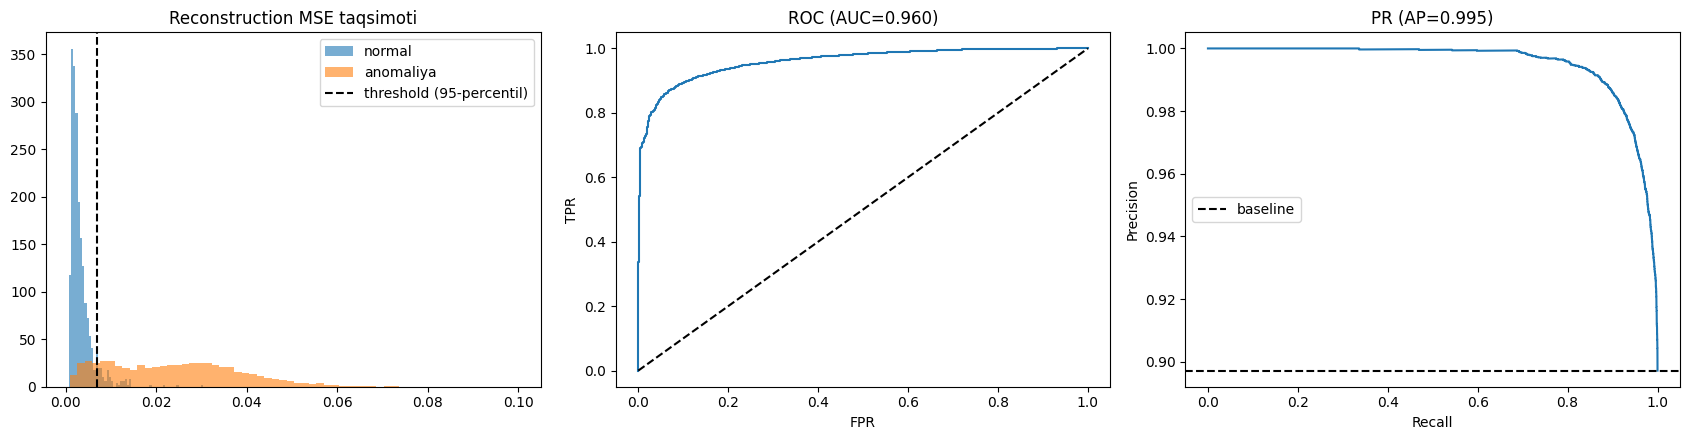

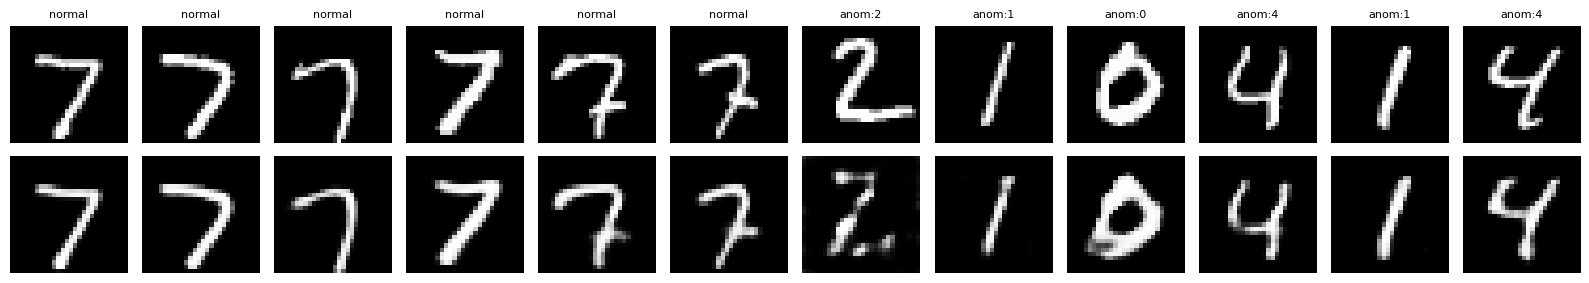

In [ ]:
ae, hist_ae = train_ae(x_ae_tr, x_ae_val)
res_ae, sweep_ae, err_test, err_val = evaluate_ae(ae, x_ae_val)
print({k: round(v, 4) for k, v in res_ae.items()})
print('Anomaliya ulushi (PR-AUC anomaliya uchun baseline): %.3f' % y_anom.mean())
display(sweep_ae.round(4))

thr95 = sweep_ae.loc[sweep_ae.percentile == 95, 'threshold'].values[0]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].hist(err_test[y_anom == 0], bins=60, alpha=.6, density=True, label='normal')
ax[0].hist(err_test[y_anom == 1], bins=60, alpha=.6, density=True, label='anomaliya')
ax[0].axvline(thr95, color='k', ls='--', label='threshold (95-percentil)')
ax[0].set_title('Reconstruction MSE taqsimoti'); ax[0].legend()
fpr, tpr, _ = roc_curve(y_anom, err_test)
ax[1].plot(fpr, tpr); ax[1].plot([0, 1], [0, 1], 'k--')
ax[1].set_title(f"ROC (AUC={res_ae['ROC_AUC']:.3f})"); ax[1].set_xlabel('FPR'); ax[1].set_ylabel('TPR')
pr_, rc_, _ = precision_recall_curve(y_anom, err_test)
ax[2].plot(rc_, pr_); ax[2].axhline(y_anom.mean(), color='k', ls='--', label='baseline')
ax[2].set_title(f"PR (AP={res_ae['PR_AUC_anomaly']:.3f})"); ax[2].set_xlabel('Recall'); ax[2].set_ylabel('Precision'); ax[2].legend()
plt.tight_layout(); plt.savefig('task9_ae_curves.png', dpi=150); plt.show()

# Qayta qurish namunalari: yuqori qator asl, pastki qator qayta qurilgan
idx = np.r_[np.where(y_anom == 0)[0][:6], np.where(y_anom == 1)[0][:6]]
rec = ae.predict(x_test[idx], verbose=0)
fig, axes = plt.subplots(2, 12, figsize=(16, 3))
for j, i in enumerate(idx):
    axes[0, j].imshow(x_test[i, ..., 0], cmap='gray'); axes[0, j].set_title('normal' if y_anom[i] == 0 else f'anom:{y_test[i]}', fontsize=8)
    axes[1, j].imshow(rec[j, ..., 0], cmap='gray')
for a in axes.ravel(): a.axis('off')
plt.tight_layout(); plt.savefig('task9_ae_recon.png', dpi=150); plt.show()

epoch 1/60 | G 0.676 | D 1.239 | 74s


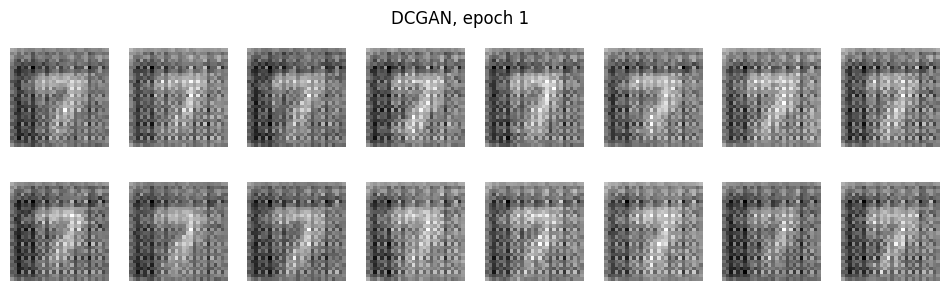

epoch 10/60 | G 0.803 | D 1.373 | 701s


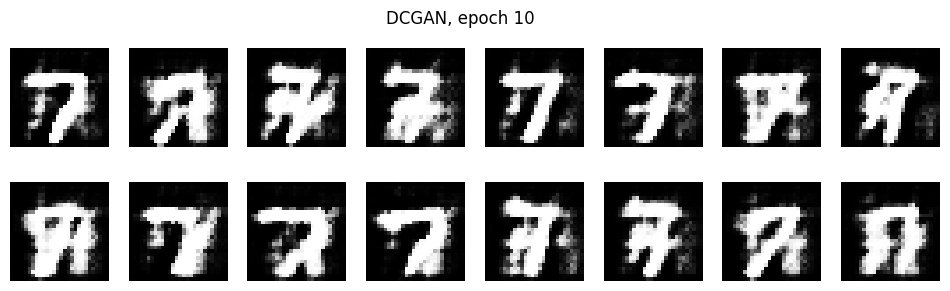

epoch 20/60 | G 0.819 | D 1.355 | 1361s


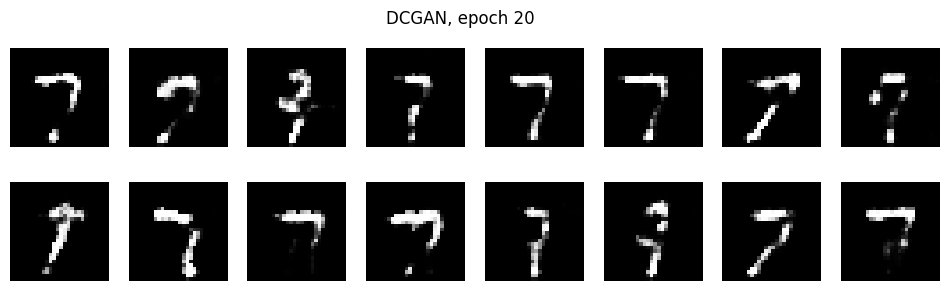

epoch 30/60 | G 0.824 | D 1.368 | 2058s


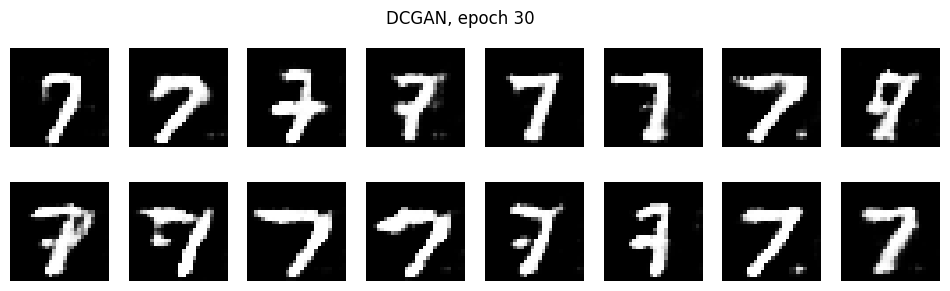

epoch 40/60 | G 0.837 | D 1.350 | 2734s


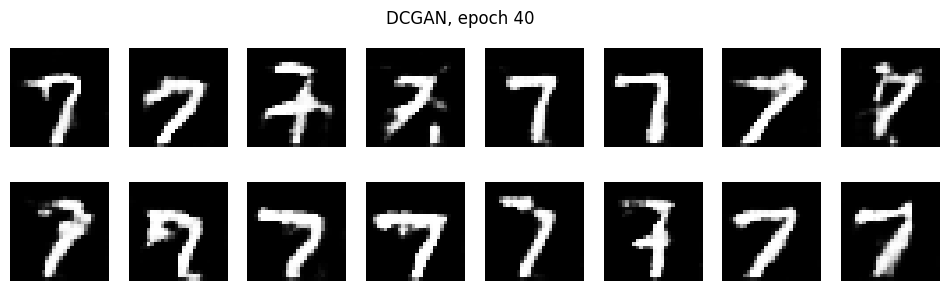

epoch 50/60 | G 0.820 | D 1.367 | 3392s


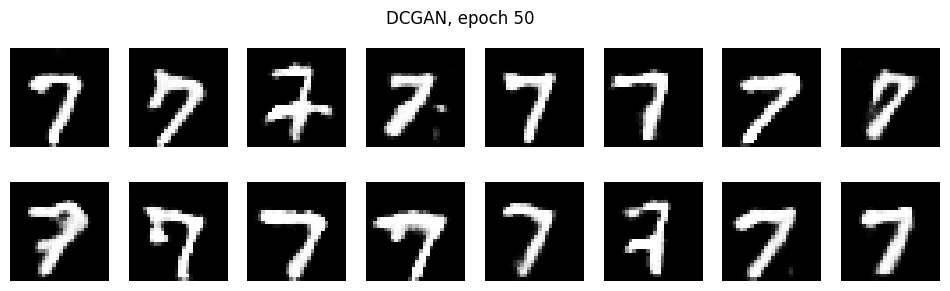

epoch 60/60 | G 0.844 | D 1.355 | 4045s


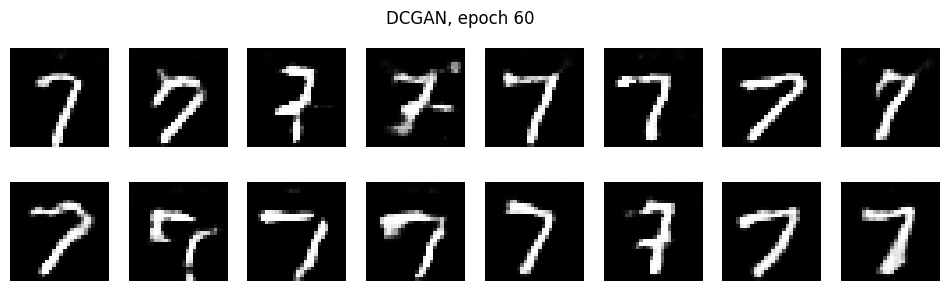

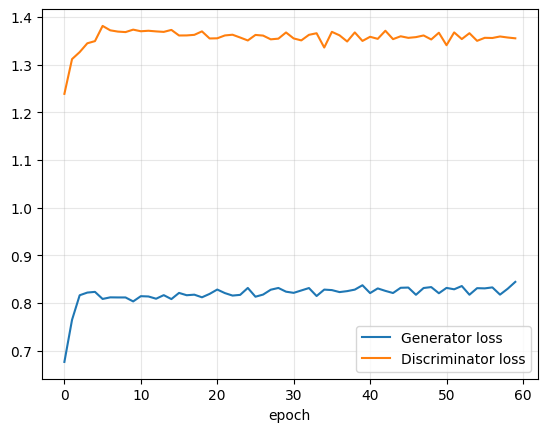

In [ ]:
def build_generator():
    set_seed()
    return models.Sequential([
        layers.Input((LATENT_GAN,)),
        layers.Dense(7 * 7 * 256, use_bias=False), layers.BatchNormalization(), layers.LeakyReLU(0.2),
        layers.Reshape((7, 7, 256)),
        layers.Conv2DTranspose(128, 5, strides=1, padding='same', use_bias=False),
        layers.BatchNormalization(), layers.LeakyReLU(0.2),
        layers.Conv2DTranspose(64, 5, strides=2, padding='same', use_bias=False),
        layers.BatchNormalization(), layers.LeakyReLU(0.2),
        layers.Conv2DTranspose(1, 5, strides=2, padding='same', activation='tanh')], name='generator')

def build_discriminator():
    set_seed()
    return models.Sequential([
        layers.Input((28, 28, 1)),
        layers.Conv2D(64, 5, strides=2, padding='same'), layers.LeakyReLU(0.2), layers.Dropout(0.3),
        layers.Conv2D(128, 5, strides=2, padding='same'), layers.LeakyReLU(0.2), layers.Dropout(0.3),
        layers.Flatten(), layers.Dense(1)], name='discriminator')      # logit

gen, disc = build_generator(), build_discriminator()
bce = tf.keras.losses.BinaryCrossentropy(from_logits=True)
g_opt = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
d_opt = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)

@tf.function
def train_step(real):
    noise = tf.random.normal([tf.shape(real)[0], LATENT_GAN])
    with tf.GradientTape() as gt, tf.GradientTape() as dt:
        fake = gen(noise, training=True)
        r, f = disc(real, training=True), disc(fake, training=True)
        g_loss = bce(tf.ones_like(f), f)
        d_loss = bce(tf.ones_like(r) * 0.9, r) + bce(tf.zeros_like(f), f)     # label smoothing
    g_opt.apply_gradients(zip(gt.gradient(g_loss, gen.trainable_variables), gen.trainable_variables))
    d_opt.apply_gradients(zip(dt.gradient(d_loss, disc.trainable_variables), disc.trainable_variables))
    return g_loss, d_loss

real_gan = (x_norm * 2.0 - 1.0).astype('float32')                            # [-1, 1]
ds_gan = (tf.data.Dataset.from_tensor_slices(real_gan)
          .shuffle(10000, seed=SEED).batch(GAN_BATCH, drop_remainder=True).prefetch(tf.data.AUTOTUNE))
fixed_noise = tf.random.normal([16, LATENT_GAN], seed=SEED)

def show_grid(epoch):
    imgs = (gen(fixed_noise, training=False).numpy() + 1) / 2
    fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
    for a, im in zip(axes.ravel(), imgs): a.imshow(im[..., 0], cmap='gray'); a.axis('off')
    fig.suptitle(f'DCGAN, epoch {epoch}'); plt.show()

g_hist, d_hist, t0 = [], [], time.time()
for ep in range(1, GAN_EPOCHS + 1):
    gl, dl = [], []
    for batch in ds_gan:
        g, d = train_step(batch); gl.append(float(g)); dl.append(float(d))
    g_hist.append(np.mean(gl)); d_hist.append(np.mean(dl))
    if ep % 10 == 0 or ep == 1:
        print(f'epoch {ep}/{GAN_EPOCHS} | G {g_hist[-1]:.3f} | D {d_hist[-1]:.3f} | {time.time()-t0:.0f}s')
        show_grid(ep)

plt.plot(g_hist, label='Generator loss'); plt.plot(d_hist, label='Discriminator loss')
plt.xlabel('epoch'); plt.legend(); plt.grid(alpha=.3); plt.savefig('task9_gan_loss.png', dpi=150); plt.show()

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
FID (real vs generated): 40.44 | FID (real vs real, reference): 11.02


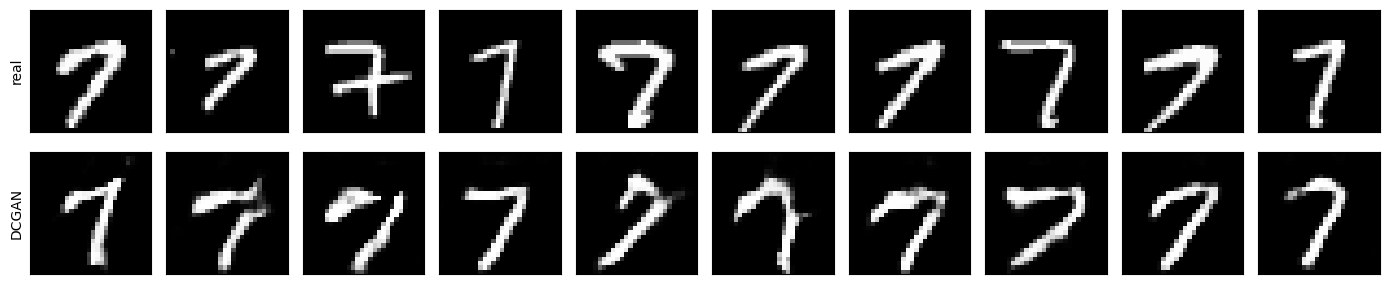

In [ ]:
gen_noise = tf.random.normal([1000, LATENT_GAN], seed=SEED + 1)
gen_imgs = np.clip((gen(gen_noise, training=False).numpy() + 1) / 2, 0, 1).astype('float32')

inc = InceptionV3(include_top=False, weights='imagenet', pooling='avg', input_shape=(299, 299, 3))

def inc_feats(x01):
    out = []
    for i in range(0, len(x01), 50):
        b = tf.image.resize(tf.convert_to_tensor(x01[i:i + 50]), (299, 299))
        b = tf.repeat(b, 3, axis=-1) * 2.0 - 1.0              # InceptionV3 uchun [-1, 1]
        out.append(inc(b, training=False).numpy())
    return np.concatenate(out)

def fid(f1, f2):
    mu1, mu2 = f1.mean(0), f2.mean(0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    covmean = np.real(sqrtm(s1.dot(s2)))
    return float(np.sum((mu1 - mu2) ** 2) + np.trace(s1 + s2 - 2 * covmean))

real_A = x_norm[:1000]; real_B = x_norm[1000:2000]
f_A, f_B, f_G = inc_feats(real_A), inc_feats(real_B), inc_feats(gen_imgs)
fid_gen  = fid(f_A, f_G)
fid_real = fid(f_A, f_B)          # real-vs-real: bu usulning "pol" qiymati (1000 namunali)
print(f'FID (real vs generated): {fid_gen:.2f} | FID (real vs real, reference): {fid_real:.2f}')

fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for j in range(10):
    axes[0, j].imshow(real_A[j, ..., 0], cmap='gray'); axes[1, j].imshow(gen_imgs[j, ..., 0], cmap='gray')
axes[0, 0].set_ylabel('real'); axes[1, 0].set_ylabel('DCGAN')
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig('task9_real_vs_gen.png', dpi=150); plt.show()

In [ ]:
ae_aug, _ = train_ae(np.concatenate([x_ae_tr, gen_imgs]), x_ae_val)   # real + 1000 sintetik
res_aug, sweep_aug, _, _ = evaluate_ae(ae_aug, x_ae_val)              # val va test faqat real

row = lambda name, r, sw: dict(model=name, **{k: round(v, 4) for k, v in r.items()},
                               F1_at_p95=round(sw.loc[sw.percentile == 95, 'f1'].values[0], 4))
summary = pd.DataFrame([row('AE (faqat real)', res_ae, sweep_ae),
                        row('AE (real + 1000 sintetik)', res_aug, sweep_aug)]).set_index('model')
summary['FID_gen_vs_real'] = [round(fid_gen, 2), round(fid_gen, 2)]
summary['FID_real_vs_real_ref'] = [round(fid_real, 2)] * 2
display(summary); summary.to_csv('task9_results.csv')

Epoch 1/40
52/52 - 14s - 275ms/step - loss: 0.1022 - val_loss: 0.0523
Epoch 2/40
52/52 - 19s - 366ms/step - loss: 0.0502 - val_loss: 0.0481
Epoch 3/40
52/52 - 11s - 220ms/step - loss: 0.0457 - val_loss: 0.0372
Epoch 4/40
52/52 - 12s - 226ms/step - loss: 0.0279 - val_loss: 0.0212
Epoch 5/40
52/52 - 12s - 226ms/step - loss: 0.0159 - val_loss: 0.0119
Epoch 6/40
52/52 - 12s - 226ms/step - loss: 0.0105 - val_loss: 0.0091
Epoch 7/40
52/52 - 21s - 396ms/step - loss: 0.0083 - val_loss: 0.0075
Epoch 8/40
52/52 - 11s - 211ms/step - loss: 0.0069 - val_loss: 0.0064
Epoch 9/40
52/52 - 21s - 407ms/step - loss: 0.0061 - val_loss: 0.0058
Epoch 10/40
52/52 - 12s - 227ms/step - loss: 0.0055 - val_loss: 0.0053
Epoch 11/40
52/52 - 20s - 392ms/step - loss: 0.0050 - val_loss: 0.0049
Epoch 12/40
52/52 - 20s - 394ms/step - loss: 0.0046 - val_loss: 0.0046
Epoch 13/40
52/52 - 12s - 225ms/step - loss: 0.0042 - val_loss: 0.0043
Epoch 14/40
52/52 - 12s - 224ms/step - loss: 0.0040 - val_loss: 0.0041
Epoch 15/40
52/

,ROC_AUC,PR_AUC_anomaly,PR_AUC_normal,F1_at_p95,FID_gen_vs_real,FID_real_vs_real_ref
model,,,,,,
AE (faqat real),0.9602,0.9952,0.7493,0.9274,40.44,11.02
AE (real + 1000 sintetik),0.9618,0.9953,0.8003,0.9199,40.44,11.02
